# Lab 8 — Morphological Image Processing


---
## Theory — What is morphological processing?

**Morpholgical Processing** is modifying and improving the shapes in an image.

 The two ingredients of every morphological operation:

1. **The image** — a binary image where white (`255`) pixels are *foreground* (the object) and black (`0`) pixels are *background*.
2. **The structuring element** (also called *kernel* or *probe*) — a small shape (e.g., 3×3 square, 5×5 circle) that you slide across the image.

### The four basic operations
<img src="https://drive.google.com/thumbnail?id=129tujHkYNk3b8US7HEqbt-WymOZgwMnA&sz=w1000" width="600">



| Operation | What it does | Formula | Effect on objects |
|---|---|---|---|
| **Erosion** | Shrinks objects | $A \ominus B$ | Removes thin parts and noise |
| **Dilation** | Grows objects | $A \oplus B$ | Fills gaps, thickens objects |
| **Opening** | Erosion then dilation | $A \circ B = (A \ominus B) \oplus B$ | Removes small noise but keeps overall size |
| **Closing** | Dilation then erosion | $A \bullet B = (A \oplus B) \ominus B$ | Fills small holes but keeps overall size |

### How to remember each one

- **Erosion eats away** at object edges → output is smaller.
- **Dilation expands** object edges → output is larger.
- **Opening = "open up" the gaps** between separated noise specks (removes noise without shrinking real objects).
- **Closing = "close up" small holes** inside objects (fills gaps without growing real objects).



---
## Task 1 — Create a Binary Image with Shapes and Noise

The lab provides this code to generate a synthetic test image with **4 shapes** and some random **salt noise**:
- A solid filled circle on the left
- A solid filled rectangle
- A hollow (outline-only) circle
- A hollow rectangle
- Plus 1000 random scattered white pixels (noise)

## Setup — Import libraries

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

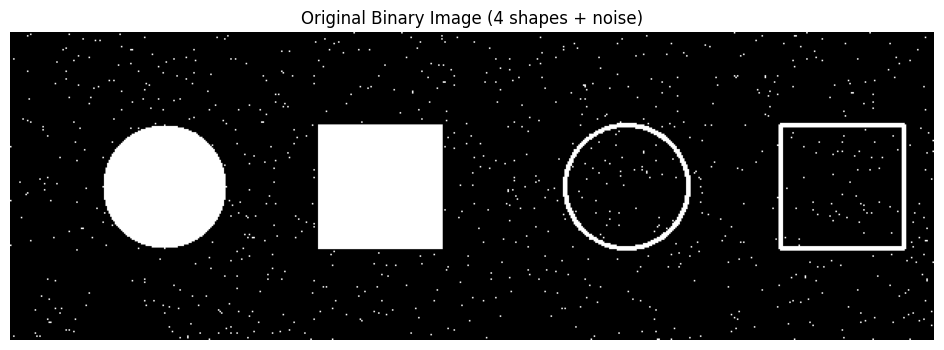

In [4]:
# Create a binary image with shapes and noise
image = np.zeros((200, 600), dtype=np.uint8)
cv2.circle(image, (100, 100), 40, 255, -1)              # Solid circle (filled) - radius=40
cv2.rectangle(image, (200, 60), (280, 140), 255, -1)    # Solid rectangle (filled) - start & end points= (200, 60), (280, 140)
cv2.circle(image, (400, 100), 40, 255, 2)               # Hollow circle (outline)
cv2.rectangle(image, (500, 60), (580, 140), 255, 2)     # Hollow rectangle (outline)

# Add small noise (1000 random white pixels)
np.random.seed(0)
for _ in range(1000):
    x, y = np.random.randint(0, 600), np.random.randint(0, 200)
    image[y, x] = 255

plt.figure(figsize=(12, 4))
plt.imshow(image, cmap='gray')
plt.title('Original Binary Image (4 shapes + noise)')
plt.axis('off')
plt.show()

---
Define the Structuring Element (5×5 Square Kernel)

The structuring element is the "shape" we slide across the image. The simplest one is a **square of all ones**:

$$K = \begin{bmatrix} 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \end{bmatrix}$$

**Why a square?** It's directionally neutral (same effect horizontally and vertically) and fast to compute. The `1`s indicate which positions in the neighborhood are "active" — for a square kernel, every neighbor counts.

In [5]:
kernel = np.ones((5, 5), np.uint8)
print("Square kernel (5×5):")
print(kernel)

Square kernel (5×5):
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]


---
## Assessment Task 1 — Apply Erosion, Dilation, Opening, Closing (Square Kernel)

For each operation we use a single OpenCV function:

| Operation | OpenCV call |
|---|---|
| Erosion | `cv2.erode(image, kernel, iterations=1)` |
| Dilation | `cv2.dilate(image, kernel, iterations=1)` |
| Opening | `cv2.morphologyEx(image, cv2.MORPH_OPEN, kernel)` |
| Closing | `cv2.morphologyEx(image, cv2.MORPH_CLOSE, kernel)` |



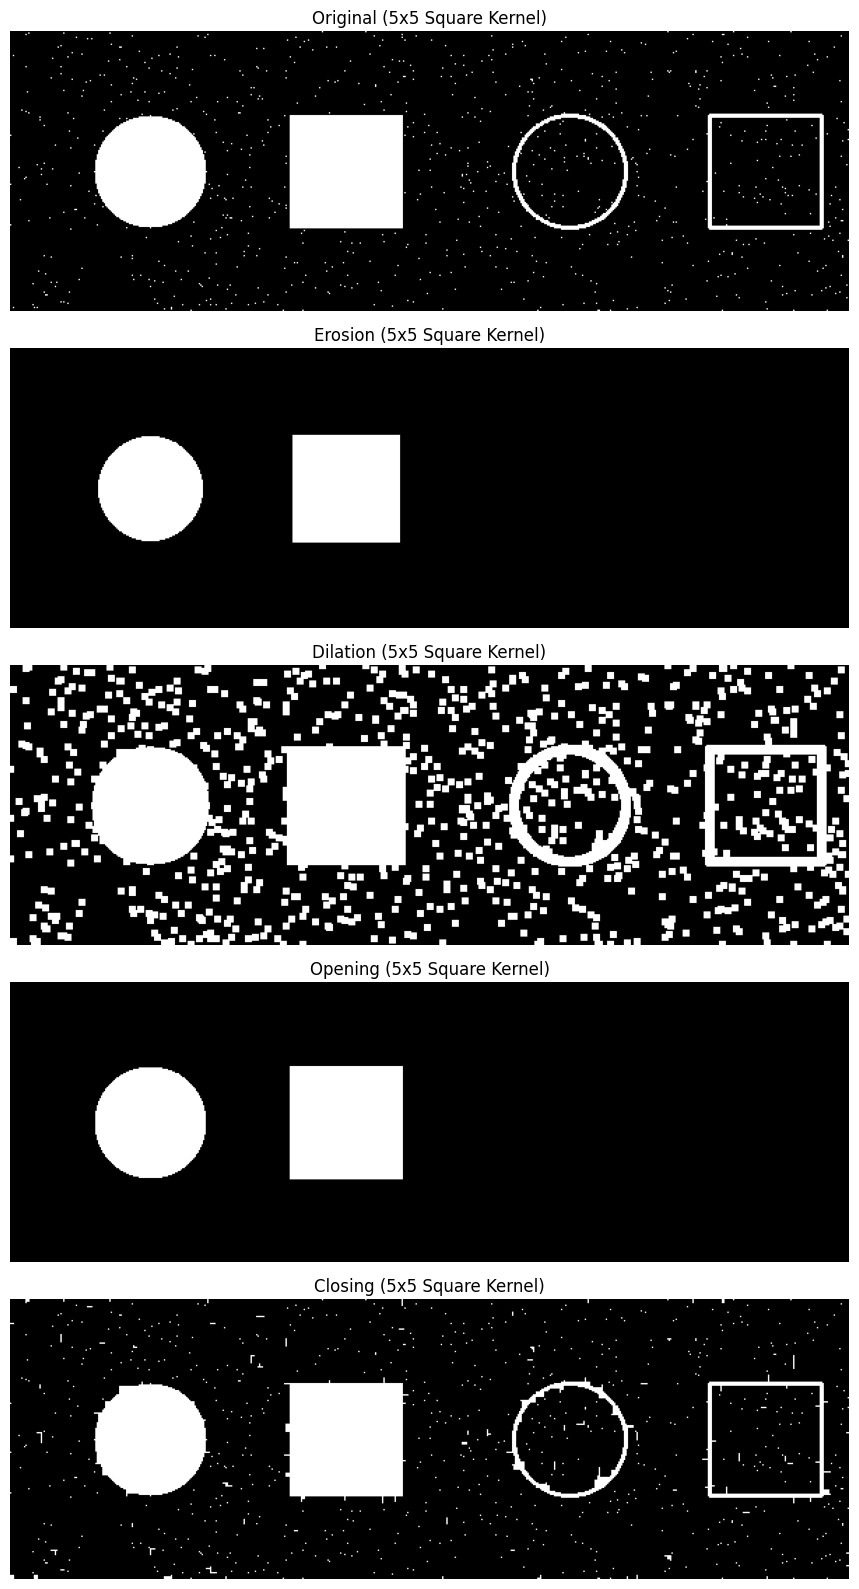

In [1]:
erosion_sq = cv2.erode(image, kernel, iterations=1)
dilation_sq = cv2.dilate(image, kernel, iterations=1)
opening_sq = cv2.morphologyEx(image, cv2.MORPH_OPEN, kernel)
closing_sq = cv2.morphologyEx(image, cv2.MORPH_CLOSE, kernel)

fig, axes = plt.subplots(5, 1, figsize=(12, 16))
titles = ["Original", "Erosion", "Dilation", "Opening", "Closing"]
imgs = [image, erosion_sq, dilation_sq, opening_sq, closing_sq]
for ax, title, im in zip(axes, titles, imgs):
    ax.imshow(im, cmap='gray')
    ax.set_title(f"{title} (5x5 Square Kernel)")
    ax.axis('off')
plt.tight_layout()
plt.show()


## Assessment Task 2 — Repeat with a Circular Kernel

Apply erosion, dilation opening and closing to the generated image in Task#1 using the following structuring element:

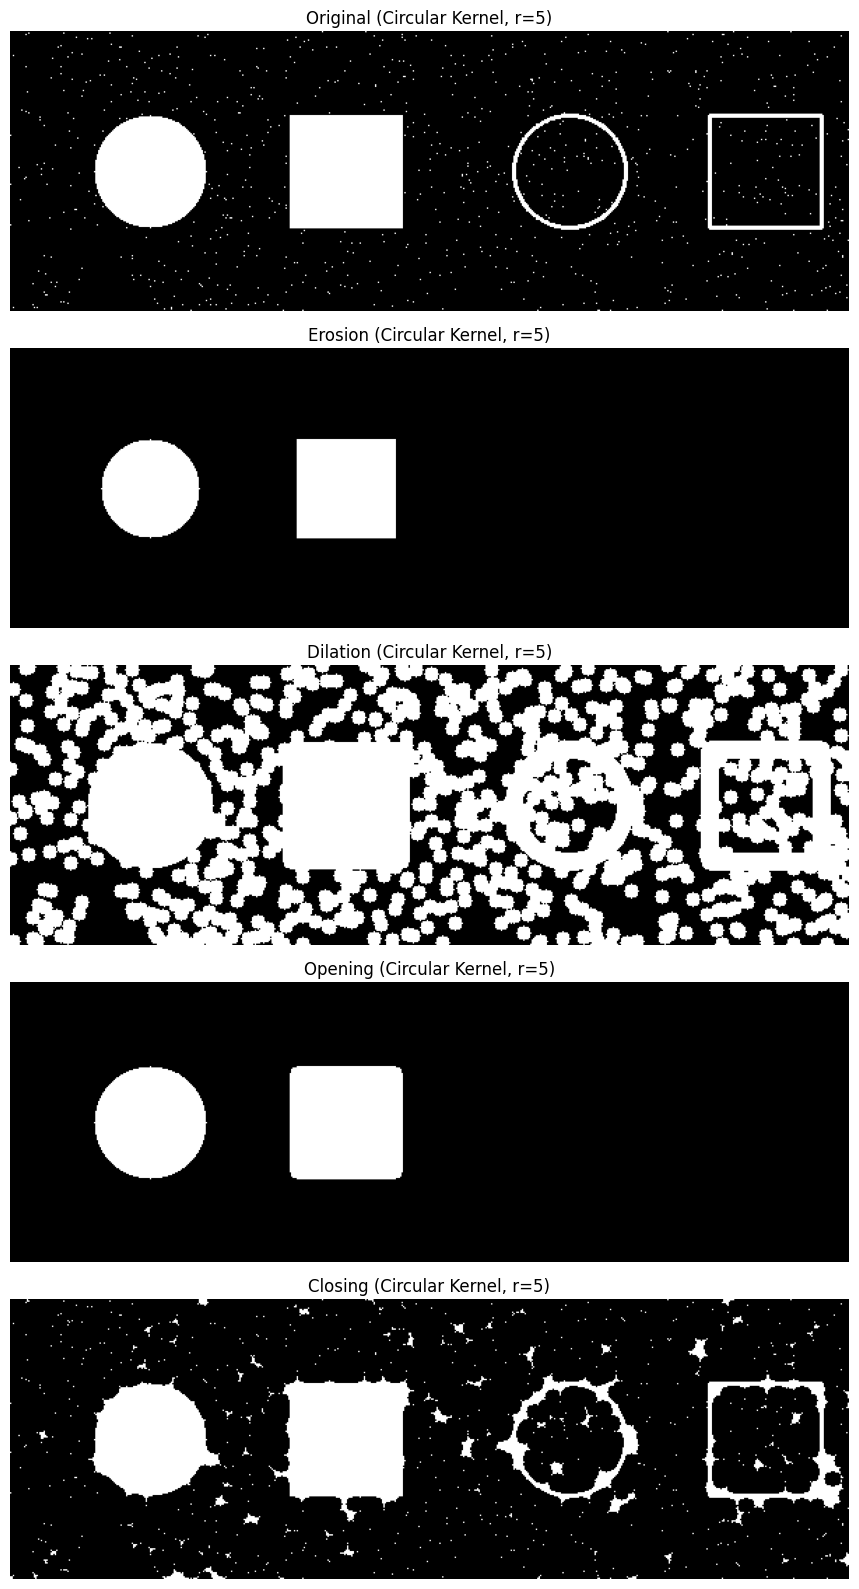

In [2]:
def circular_structuring_element(radius):
    """Creates a binary circular structuring element (exact circle)"""
    size = 2 * radius + 1                    # Ensure kernel size is odd
    kernel = np.zeros((size, size), dtype=np.uint8)
    cv2.circle(kernel, (radius, radius), radius, 1, -1)  # Draw filled circle
    return kernel

# Define radius
radius = 5
circle_kernel = circular_structuring_element(radius)

# Apply the same four operations using the circular kernel
erosion_c = cv2.erode(image, circle_kernel, iterations=1)
dilation_c = cv2.dilate(image, circle_kernel, iterations=1)
opening_c = cv2.morphologyEx(image, cv2.MORPH_OPEN, circle_kernel)
closing_c = cv2.morphologyEx(image, cv2.MORPH_CLOSE, circle_kernel)

fig, axes = plt.subplots(5, 1, figsize=(12, 16))
titles = ["Original", "Erosion", "Dilation", "Opening", "Closing"]
imgs_c = [image, erosion_c, dilation_c, opening_c, closing_c]
for ax, title, im in zip(axes, titles, imgs_c):
    ax.imshow(im, cmap='gray')
    ax.set_title(f"{title} (Circular Kernel, r={radius})")
    ax.axis('off')
plt.tight_layout()
plt.show()


## Assessment Task 3 — Difference Between Square vs Circular Kernel

 In your own words, explain the difference between the results in Task#1 and Task#2



**Answer:**

The square kernel and the circular kernel both perform the same four operations, but the *shape* of the structuring element changes how the effect spreads across the image:

- **Square kernel (5×5):** Erosion and dilation grow/shrink objects uniformly along rows and columns, but because the kernel itself has sharp corners, the resulting shapes pick up slightly **blocky / squared-off corners** — most visible on the circle's outline, which comes out looking a bit more "octagonal" after dilation.

- **Circular kernel (radius 5):** Because the structuring element is isotropic (equal reach in every direction, not just horizontal/vertical), erosion and dilation grow or shrink the shapes **uniformly in all directions**, so curved edges (like the circle) stay smooth and round instead of becoming blocky. Straight edges (like the rectangle) also come out with more naturally rounded corners.

- **Noise removal (Opening):** Both kernels remove the scattered single-pixel noise, since a single white pixel can never survive an erosion step regardless of the kernel's shape. The circular kernel's opening looks slightly "cleaner" on curved shapes because it doesn't introduce the small directional artifacts the square kernel can.

- **Hole filling (Closing):** Both kernels close small gaps in the hollow shapes similarly well, but the circular kernel again preserves the rounded look of the circle's outline better than the square kernel does.

**In short:** the square kernel is faster and directionally simple, but distorts curved shapes slightly; the circular kernel is more computationally expensive (not just 1s and 0s uniformly) but preserves the natural (isotropic) shape of objects — especially circles — much better.
